## 1. Catalog overview (categories, brands, prices)

In [2]:
import re
from collections import Counter
from pathlib import Path

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

data_path = Path("../data/raw/products.csv")

df = pd.read_csv(data_path)

print("Shape", df.shape)
df.head()


Shape (4207, 12)


,product_id,title,description,brand,category,price,specs,features,image_url,source_url,rating,source
0,alibaba:10000024495003,60kW 80kW 120kW DC Fast EV Charging Station CC...,60kW 80kW 120kW DC Fast EV Charging Station CC...,NaN,charger,4834.36,"{""Supplier"": ""Luoyang Grasen Power Technology ...",[],https://s.alicdn.com/@sc04/kf/H7e1758216a52445...,https://www.alibaba.com/product-detail/60kW-80...,NaN,alibaba
1,alibaba:10000026629603,5V USB Charger Compact and Easy to Carry Switc...,5V USB Charger Compact and Easy to Carry Switc...,NaN,charger,1.64,"{""Supplier"": ""GOOD OPPORTUNITY ELECTRONIC CO.,...",[],https://s.alicdn.com/@sc04/kf/S6c1ce38854ba482...,https://www.alibaba.com/product-detail/5V-USB-...,NaN,alibaba
2,alibaba:10000027315547,GOE GS-T-PD20W-1C Type-C PD20W Power Supply 5V...,GOE GS-T-PD20W-1C Type-C PD20W Power Supply 5V...,NaN,charger,3.49,"{""Supplier"": ""GOOD OPPORTUNITY ELECTRONIC CO.,...",[],https://s.alicdn.com/@sc04/kf/S2d38885a5283493...,https://www.alibaba.com/product-detail/GOE-GS-...,NaN,alibaba
3,alibaba:10000029436982,GOE 380W GaN Desktop Charger with Digital Disp...,GOE 380W GaN Desktop Charger with Digital Disp...,NaN,charger,27.13,"{""Supplier"": ""GOOD OPPORTUNITY ELECTRONIC CO.,...",[],https://s.alicdn.com/@sc04/kf/Scf026145ab014dc...,https://www.alibaba.com/product-detail/GOE-380...,NaN,alibaba
4,alibaba:1600155435446,Ldnio A2318C 20W Fast Eu US Uk Portable PD QC3...,Ldnio A2318C 20W Fast Eu US Uk Portable PD QC3...,NaN,charger,4.06,"{""Supplier"": ""Shenzhen Siyoteam Technology Co....",[],https://s.alicdn.com/@sc04/kf/H5be34a25068c484...,https://www.alibaba.com/product-detail/Ldnio-A...,4.8,alibaba


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4207 entries, 0 to 4206
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   product_id   4207 non-null   str    
 1   title        4207 non-null   str    
 2   description  4207 non-null   str    
 3   brand        3770 non-null   str    
 4   category     4207 non-null   str    
 5   price        4102 non-null   float64
 6   specs        4207 non-null   str    
 7   features     4207 non-null   str    
 8   image_url    4207 non-null   str    
 9   source_url   4207 non-null   str    
 10  rating       1710 non-null   float64
 11  source       4207 non-null   str    
dtypes: float64(2), str(10)
memory usage: 394.5 KB


In [4]:
df.describe()

,price,rating
count,4102.000000,1710.000000
mean,397.865717,4.146754
std,800.089161,0.526045
min,0.210000,1.000000
25%,22.000000,3.900000
50%,118.175000,4.200000
75%,438.750000,4.400000
max,12999.000000,5.000000


In [5]:
df.select_dtypes(include=['str']).describe()

,product_id,title,description,brand,category,specs,features,image_url,source_url,source
count,4207,4207,4207,3770,4207,4207,4207,4207,4207,4207
unique,4207,4205,4031,445,29,3786,2866,4050,4207,8
top,alibaba:10000024495003,Apple MagSafe Charger 25W (OFF: $20),This pre-owned or refurbished product has been...,Apple,computer-accessories,{},[],https://s3.ap-southeast-1.amazonaws.com/upload...,https://www.alibaba.com/product-detail/60kW-80...,ptc_computer
freq,1,2,76,243,726,90,1243,10,1,1247


Category Count: category
computer-accessories    726
smartphone              688
tablet                  313
headphones              289
tv                      282
laptop                  231
computer                174
smartwatch              172
phone-case              167
powerbank               128
computer-components     115
gaming                  108
tablet-case             105
keyboard                 94
printer                  94
speaker                  87
charger                  85
earbuds                  82
adapter-cable            71
monitor                  58
mini_pc                  45
earphones                21
watch-straps             17
audio                    15
apple                    14
desktop                  10
handheld                 10
wireless-charger          5
e_reader                  1


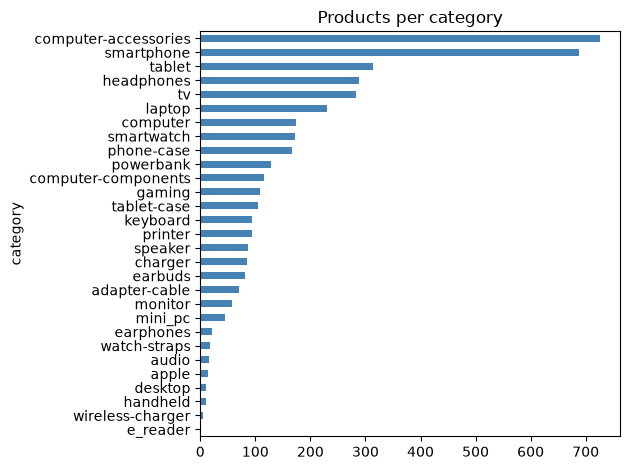

In [ ]:

category_count = df["category"].value_counts()
print("Category Count:", category_count)

category = category_count.sort_values().plot.barh(color="steelblue")
category.set_title("Products per category")
category_graph = plt
category_graph.tight_layout()
category_graph.show()

Brand Count: brand
Apple        243
Logitech     181
Eg           162
Samsung      160
SAMSUNG      159
            ... 
Planet         1
Cisco          1
PHOINKAS       1
Tally          1
PANASONIC      1
Name: count, Length: 445, dtype: int64


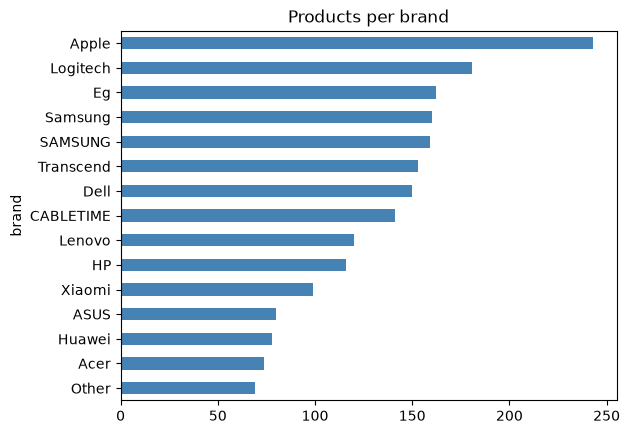

In [15]:
brand_count = df["brand"].value_counts()
print("Brand Count:", brand_count)

brand = brand_count.head(15).sort_values().plot.barh(color="steelblue")
brand.set_title("Products per brand")
brand_graph = plt

brand_graph.show() 

## 2. Missing values and data quality

## 3. Intent label distribution

## 4. Query characteristics (length, question words, model numbers)